# C03 — 2라인 중형 전진 "대차번호 이상" 에러 (2026-10-31, G-02-018 · G-02-021 · M-02-04-2-3)

정리본: [`cases/C03.md`](cases/C03.md). 이 노트북은 그 근거를 다시 만든다 (DB 는 캐시가 있으면 안 감).

| 단계 | 내용 |
|---|---|
| 1 | 일지 내용 (같은 구조의 9-14 후진 쪽 기록 포함) |
| 2 | PLC — "전진 대차번호 이상"은 무엇을 보나 (`금형CY_번호인식.il`) |
| 3 | 10-31 번호 불일치 10번 = 1번 대차가 두 번 세어진 순간 |
| 4 | 날짜별 — 1번 대차 이중 감지는 10-30·31에만 있었다 |
| 5 | 재감지는 1번만의 일이 아니다 — 대차 × 날짜 |
| 6 | 조치 시점 (10-31 16:29 ~ 16:39) |
| 7 | 모델 — 가동일 기록 판정: P00451 "센서 재감지"는 9-10부터 매일 켜져 있었다 |
| 8 | 실제 엣지 경고 (W0069 → 조치 뒤 W0171 …) |
| 9 | 조치 뒤 경고 — 같은 원인의 잔여 |
| 10 | 같은 유닛의 주입 시간 경고(W0148)는 무관 |
| 11 | 후진 쪽 같은 사례 — 09-14 1번 대차 센터축 볼트 |

In [1]:
import sys, json; sys.path.insert(0, "..")
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
from review_lib import paths, db, backend, plot
pd.set_option("display.width", 250); pd.set_option("display.max_rows", 200); pd.set_option("display.max_columns", 60)
FIGS = paths.CHECK_DIRS["conveyor"] / "figs"; FIGS.mkdir(exist_ok=True)
RCACHE = paths.CACHE_DIR / "replay"; RCACHE.mkdir(parents=True, exist_ok=True)
HIST = json.load(open(paths.MODEL_VERSIONS["v2.2"]["backend"] / "data" / "conveyor_core_history.json"))
IL = Path("/Users/jeonjae/Desktop/KTA/HDI_Relay/backend/IL_file")

#: 번호 인식 태그 — 운영 모델 태그가 아니다. 이 사건을 보려고 따로 뽑는다 (group md_num, 하루 약 2초)
#: D05200·D05210(유닛 대차 카운터)은 진단 스냅샷 때만 저장돼 하루 20번쯤만 바뀐다 → 통과 추적에 못 쓴다
MD_TAGS = ["P00450", "P00451", "P00458", "P00459", "D05200", "D05210", "D05299", "M00042", "M00045",
           "M00601", "M00611", "AL_Line_Word", "MD_FWD_Zone_In_PS_CHK_Err", "Now_Actual_Wagon_Num",
           "R00055", "R00060", "Hz_In_Conv", "Conv_Run_Out", "Auto_Running_PL"]
DAYS = pd.date_range("2026-09-10", "2026-11-12")
LOG_TIMES = [("2026-10-31 12:00", "2026-10-31 12:30"), ("2026-10-31 13:30", "2026-10-31 14:00")]   # 공무반 점검
ADJ = (pd.Timestamp("2026-10-31 16:29:42"), pd.Timestamp("2026-10-31 16:38:40"))                 # 데이터로 찾은 조정 구간 (6절)
UNIT = {"fwd": dict(counter="R00055", first="P00450", bit="M00042", name="전진"),
        "rev": dict(counter="R00060", first="P00458", bit="M00045", name="후진")}


def raw_day(d):
    return db.fetch_day(d, MD_TAGS, group="md_num")


def md_passes(raw, counter="R00055", first="P00450"):
    """진입 센서 통과 하나 = 한 행.

    - 카운터(R00055·R00060)는 진입 센서가 켜질 때마다 1로 돌아간다(`Air_Supply_Unit.il` 254~257).
      DB가 놓친 짧은 펄스도 카운터가 떨어진 것으로 보인다. 50 넘게 떨어지면 1차 리셋(새 통과), 2~50이면 2차 리셋(재감지).
    - 대차 번호는 PLC와 같은 기준: 1번 감지 센서(P00450·P00458)가 켜진 샘플 앞 3초 안의 마지막 1차 리셋이 1번 대차.
      1번 감지 펄스는 짧아 DB가 가끔 놓친다 → 그때는 42 다음을 1로 이어 간다.
    - gap_s: 1차 리셋 → 2.5초 안 첫 2차 리셋까지 (없으면 NaN). early: 리셋 직전 카운터 값(정상 피치 약 133, 앞 펄스면 119~124).
    """
    r = raw[counter].ffill().to_numpy(float); t = raw.index.to_numpy()
    dr = np.diff(r, prepend=r[0])
    prim = np.flatnonzero(dr < -50)
    sec = np.flatnonzero((dr <= -2) & (dr >= -50))
    anchor = set()
    for i in np.flatnonzero(raw[first].fillna(0).to_numpy() > 0):
        c = prim[(t[prim] <= t[i]) & (t[prim] >= t[i] - np.timedelta64(3, "s"))]
        if len(c):
            anchor.add(c[-1])
    wag, cur = [], None
    for i in prim:
        cur = 1 if i in anchor else (None if cur is None else cur % 42 + 1)
        wag.append(cur)
    k = np.searchsorted(sec, prim, side="right")
    ok = k < len(sec)
    j = sec[np.minimum(k, len(sec) - 1)] if len(sec) else np.zeros(len(prim), int)
    g = (t[j] - t[prim]) / np.timedelta64(1, "s")
    gap = np.where(ok & (g <= 2.5), g, np.nan)
    return pd.DataFrame({"t": t[prim], "wagon": pd.array(wag, dtype="Int64"), "gap_s": gap,
                         "early": -dr[prim] + r[prim] - 1}).assign(rearm=lambda d: d.gap_s.notna())

## 1. 일지

In [2]:
acts = pd.read_csv(paths.ACTIONS_DIR / "actions_conveyor.csv")
acts[acts.incident_id == "C03"][["작업ID", "journal", "start_dt", "end_dt", "설비분류", "설비상세", "조치", "결과", "담당", "출처"]]

,작업ID,journal,start_dt,end_dt,설비분류,설비상세,조치,결과,담당,출처
3,G-02-018,공무반,2026-10-31 12:00:00,2026-10-31 12:30:00,캐리어,40~4번 대차 중형 전진 센서 에러,점검,결과 미기재,황성빈,gonmu_daily_2026-10-26_2026-11-05.xls NO.18
4,G-02-021,공무반,2026-10-31 13:30:00,2026-10-31 14:00:00,에어주입장치,중형 전진 에어주입장치 센서 에러,점검,결과 미기재,황성빈,gonmu_daily_2026-10-26_2026-11-05.xls NO.21
6,M-02-04-2-3,기계실,NaN,NaN,캐리어,2라인 중형 전진 대차번호 이상 에러 6회 발생; 2라인 기존 센서 및 브라켓 위치...,기존 센서 및 브라켓 위치 조정,라인 정상동작,"안치삼,신경오 / 강상조 외 2명",261026-261105 기계실업무일지.pdf p.4 NO.2-3


In [3]:
# 같은 PLC 구조(후진 쪽)의 과거 기록 — 2라인 09-14. 검토 구간(10-16~) 밖이지만 11절에서 같은 원리를 확인한다
full = pd.read_excel(paths.FILTERING_XLSX, sheet_name="전체")
txt = full[["설비상세", "이슈", "조치"]].fillna("").astype(str).agg(" ".join, axis=1)
full[(full.작업일.astype(str).str.startswith("2026-09-14")) & txt.str.contains("1번 대차|중형 후진")][
    ["작업일", "라인번호", "설비상세", "조치", "기록시간", "작업ID"]]

,작업일,라인번호,설비상세,조치,기록시간,작업ID
48,2026-09-14,2,중형 후진 에어주입장치 센서 에러,1번 대차 센터축 고정 볼트 파손 확인,07:30~08:30,C-053
50,2026-09-14,2,1번 대차 센터축 고정 볼트 파손,볼트 교체,10:50~11:30,C-060


## 2. PLC — "전진 대차번호 이상"은 무엇을 보나

`HDI_Relay/backend/IL_file/금형CY_번호인식.il` (UTF-16). 전진 Unit은 자기 대차 카운터(`D05200`)를 따로 센다.

- 진입 센서 P00451이 켜질 때마다 +1, **1번 감지 센서 P00450이 같이 켜져 있으면 1**로 맞춘다(2~12줄).
- 42를 넘었는데 P00450이 없으면 `M00601`(1번 감지 누락)을 켜고 1로 맞춘다(14~20줄).
- 센 번호를 43칸 시프트 레지스터에 밀어 넣고(22~24줄), **지금 번호 = 한 바퀴 전 같은 칸의 번호**면 `M00042` = 1(67~68줄).
  `Alarm.il` 55~58줄: `M00042`가 꺼지면 알람 110 "전진 대차번호 이상".
- **2회 방지**(73~80줄): P00451이 켜지면 `K00051`을 걸어 다음 켜짐을 무시한다. 카운터 R00055가 80·81이 되거나 **P00450이 켜지면** 푼다.
  → 다른 대차에서는 P00451이 한 대 안에서 두 번 켜져도(재감지) 한 번만 센다. **1번 대차에서는 P00450이 방지를 풀어 버려 두 번 센다.**
  한 바퀴에 시프트가 한 번 더 들어가 번호가 한 칸 밀리고, `M00042`가 꺼져 알람이 난다.

후진 Unit도 같은 틀이다(P00459 · P00458 · `D05210` · `K00052` · `M00045`, 81~160줄, 알람 111).

In [4]:
def show(f, a, b):
    il = (IL / f).read_text(encoding="utf-16").splitlines()
    print(f"[{f}]"); print("\n".join(f"{i:4d}  {il[i - 1]}" for i in range(a, b + 1))); print()

show("금형CY_번호인식.il", 1, 26)      # P00451 ↑ → INC D05200, P00450 이면 1, 42 넘고 P00450 없으면 M00601
show("금형CY_번호인식.il", 67, 80)     # M00042 = 한 바퀴 전과 같은가 / 2회 방지 K00051 (P00450 이 풀어 줌)
show("Alarm.il", 55, 62)               # NOT M00042 → 알람 110 전진 대차번호 이상 / NOT M00045 → 111 후진
show("Air_Supply_Unit.il", 254, 257)   # R00055 는 P00451 ↑ 마다 1 로 → 짧은 펄스도 카운터에 남는다
dev = pd.read_csv("/Users/jeonjae/Desktop/KTA/HDI_Relay/backend/mapping_csv/Device_Description.csv", header=None)
dev[dev[0].isin(["P00450", "P00451", "P00458", "P00459"])]

[금형CY_번호인식.il]
   1  CMT	///////////////  전진 대차번호 쉬프트 //////////////////
   2  LOAD	P00451
   3  OUT	M00600
   4  LOAD	_ON
   5  ADD	Max_Waggon_Num 5301 D05202
   6  LOADP	M00600
   7  AND	Conv_Brake_Time
   8  AND NOT	K00051
   9  INCP	D05200
  10  MPUSH
  11  AND	P00450
  12  MOV	1 D05200
  13  MLOAD
  14  AND>	D05200 Max_Waggon_Num
  15  MPUSH
  16  AND NOT	P00450
  17  SET	M00601
  18  MPOP
  19  AND	M00601
  20  MOV	1 D05200
  21  MLOAD
  22  MOVP	D05200 D05300
  23  MPOP
  24  WSFTP	D05300 #D05202
  25  LOAD	Reset_Sw
  26  RST	M00601

[금형CY_번호인식.il]
  67  LOAD=	D05200 #D05202
  68  OUT	M00042
  69  CMT	////////////////  대차Dog 감지불량 번호 쓰기 //////////////////
  70  LOAD	MD_FWD_Zone_In_PS_CHK_Err
  71  ORP	M00601
  72  MOVP	D05200 D05299
  73  CMT	////////////////  전진 대차번호 쉬프트 2회방지   //////////////////
  74  LOADP	M00600
  75  SET	K00051
  76  LOAD	P00450
  77  OR=	R00055 80
  78  OR=	R00055 81
  79  AND NOT	Conv_Stop_CHK_Time
  80  RST	K00051

[Alarm.il]
  55  LOAD NOT	M00042
  56  M

,0,1,2,3
2376,P00450,BIT,1,전진Unit 캐리어 1번감지
2377,P00451,BIT,1,전진Unit 캐리어 진입감지
2384,P00458,BIT,1,후진Unit 캐리어 1번감지
2385,P00459,BIT,1,후진Unit 캐리어 진입감지


## 3. 10-31 번호 불일치 10번 = 1번 대차가 두 번 세어진 순간

DB에서 `M00042`가 꺼진 순간(번호 불일치)을 모두 찾고, 그 앞 3초 안의 P00451 통과를 붙인다.
**10번 모두 PLC 기준 1번 대차이고, 10번 모두 본 감지 0.5~1초 앞에 짧은 펄스(앞 펄스)가 먼저 있었다.**

- 앞 펄스에서 카운터는 42 → 43이 되고 P00450은 아직 꺼져 있다 → `M00601` 켜짐, 1로 맞춤 (시프트 1).
- 0.5~1초 뒤 본 감지 때 P00450이 켜져 있다 → 2회 방지가 풀려 있어 한 번 더 센다 (시프트 2) → 번호 한 칸 밀림 → 알람 110.
  그 뒤 11~49초 안에 라인이 섰다(15:18·16:28은 정지 전에 번호가 먼저 복구됐다). 번호는 1~4분 안에 복구됐다.
- 앞 펄스 간격은 두 가지다: 약 1.0초(리셋 직전 카운터 124~125, 표식 14카운트 앞) 7번, 약 0.5초(128~129, 7카운트 앞) 3번.
- 14:13·15:08은 P00450 펄스가 DB 샘플 사이에 끼어 안 찍혔지만 카운터 모양은 같다.

In [5]:
r31 = raw_day("2026-10-31")
p31 = md_passes(r31)

def mismatch_events(raw, passes, bit="M00042", latch="M00601"):
    m = raw[bit].fillna(1)
    rows = []
    for t in raw.index[m.diff() == -1]:
        w = passes[(passes.t <= t) & (passes.t >= t - pd.Timedelta("3s"))]
        a = raw.loc[t:t + pd.Timedelta("5min")]
        stop = a.index[a.Conv_Run_Out.fillna(1) == 0]
        back = a.index[a[bit] == 1]
        lat = raw.loc[t - pd.Timedelta("3s"):t, latch].max()
        rows.append({"불일치": f"{t:%H:%M:%S}",
                     "통과 시작(앞 펄스)": f"{w.t.iloc[-1]:%H:%M:%S}" if len(w) else None,
                     "PLC 대차": int(w.wagon.iloc[-1]) if len(w) and pd.notna(w.wagon.iloc[-1]) else None,
                     "앞 펄스→본 감지(초)": round(w.gap_s.iloc[-1], 2) if len(w) else None,
                     "리셋 직전 카운터": int(w.early.iloc[-1]) if len(w) else None,
                     "1번 감지 누락 비트": int(lat) if lat == lat else None,
                     "라인 정지": f"{stop[0]:%H:%M:%S}" if len(stop) else None,
                     "번호 복구": f"{back[0]:%H:%M:%S}" if len(back) else None})
    return pd.DataFrame(rows)

EV31 = mismatch_events(r31, p31)
EV31

,불일치,통과 시작(앞 펄스),PLC 대차,앞 펄스→본 감지(초),리셋 직전 카운터,1번 감지 누락 비트,라인 정지,번호 복구
0,06:20:20,06:20:19,1,1.04,124,1,06:20:31,06:24:13
1,11:30:47,11:30:46,1,0.61,129,1,11:30:58,11:31:25
2,12:07:57,12:07:56,1,1.04,125,1,12:08:45,12:10:12
3,12:39:37,12:39:36,1,1.03,124,1,12:40:26,12:40:27
4,14:13:16,14:13:15,1,0.51,128,1,14:14:05,14:14:10
5,14:59:07,14:59:06,1,1.04,125,1,14:59:56,15:00:32
6,15:08:59,15:08:58,1,0.52,128,1,15:09:34,15:09:41
7,15:18:24,15:18:23,1,1.03,125,1,15:19:11,15:18:58
8,16:19:16,16:19:15,1,1.03,125,1,16:20:05,16:20:30
9,16:28:53,16:28:52,1,1.04,124,1,16:29:42,16:29:14


In [6]:
# 첫 번째(06:20) 원시 신호 — 42번(앞 펄스 + 본 감지, 평소 모양)과 1번(10-31에 새로 생긴 같은 모양)
w = r31.loc["2026-10-31 06:19:50":"2026-10-31 06:20:35",
            ["P00450", "P00451", "R00055", "M00601", "M00042", "AL_Line_Word", "Now_Actual_Wagon_Num", "Conv_Run_Out"]].copy()
w["dR"] = w.R00055.diff()
w["리셋"] = np.where(w.dR < -50, "1차", np.where(w.dR <= -2, "2차(재감지)", ""))
w["PLC 대차(=Now−26)"] = (w.Now_Actual_Wagon_Num - 27) % 42 + 1
w[(w.리셋 != "") | (w[["P00450", "M00601", "M00042", "Conv_Run_Out"]].diff().abs().sum(axis=1) > 0)]

,P00450,P00451,R00055,M00601,M00042,AL_Line_Word,Now_Actual_Wagon_Num,Conv_Run_Out,dR,리셋,PLC 대차(=Now−26)
Time,,,,,,,,,,,
2026-10-31 06:19:55.997422,0.0,0.0,7.0,0.0,1.0,0.0,25.0,1.0,-132.0,1차,41.0
2026-10-31 06:20:06.819974,0.0,0.0,2.0,0.0,1.0,0.0,26.0,1.0,-119.0,1차,42.0
2026-10-31 06:20:07.835462,0.0,1.0,5.0,0.0,1.0,0.0,26.0,1.0,-3.0,2차(재감지),42.0
2026-10-31 06:20:19.654522,0.0,0.0,2.0,0.0,1.0,0.0,27.0,1.0,-123.0,1차,1.0
2026-10-31 06:20:20.185962,0.0,0.0,7.0,1.0,1.0,0.0,27.0,1.0,5.0,,1.0
2026-10-31 06:20:20.693692,1.0,1.0,3.0,1.0,0.0,110.0,27.0,1.0,-4.0,2차(재감지),1.0
2026-10-31 06:20:21.353439,0.0,0.0,10.0,1.0,0.0,110.0,27.0,1.0,7.0,,1.0
2026-10-31 06:20:31.616898,0.0,0.0,103.0,1.0,0.0,110.0,28.0,0.0,5.0,,2.0


## 4. 날짜별 — 1번 대차 이중 감지는 10-30·31에만 있었다

09-10 ~ 11-12 모든 가동일. 전진·후진 각각 1번 대차 통과 중 이중 감지(2.5초 안 재감지) 수와 번호 불일치(`M00042`·`M00045` 꺼짐) 수.
날짜는 달력 날짜(00~24시)다.

In [7]:
f = RCACHE / "c03_md_passes.pkl"
if f.exists():
    MP, MISM = pd.read_pickle(f)
else:
    parts, mism = [], []
    for d in DAYS:
        raw = raw_day(d)
        if len(raw) < 20000:          # 휴일·정지일
            continue
        for u, c in UNIT.items():
            parts.append(md_passes(raw, c["counter"], c["first"]).assign(unit=u, day=d.strftime("%m-%d")))
            mism.append(dict(day=d.strftime("%m-%d"), unit=u, n=int((raw[c["bit"]].fillna(1).diff() == -1).sum())))
    MP, MISM = pd.concat(parts, ignore_index=True), pd.DataFrame(mism)
    pd.to_pickle((MP, MISM), f)

def daily(u):
    p = MP[MP.unit == u]
    rate = p[p.wagon.notna()].groupby(["day", "wagon"]).rearm.mean().unstack()
    w1 = p[p.wagon == 1].groupby("day").rearm.agg(["size", "sum"])
    return pd.DataFrame({"재감지율": p.groupby("day").rearm.mean().round(3),
                         "재감지 대차(≥10%)": (rate >= 0.10).sum(axis=1),
                         "1번 통과": w1["size"], "1번 이중": w1["sum"].astype(int),
                         "번호 불일치": MISM[MISM.unit == u].set_index("day").n})

D = pd.concat({"전진(P00451)": daily("fwd"), "후진(P00459)": daily("rev")}, axis=1)
D

전진(P00451)                                 후진(P00459)                                
            재감지율 재감지 대차(≥10%) 1번 통과 1번 이중 번호 불일치       재감지율 재감지 대차(≥10%) 1번 통과 1번 이중 번호 불일치
day                                                                                        
09-10      0.220           11   107     0      0      0.032            2   107     0      0
09-11      0.221           11   106     0      0      0.021            3   106     1      1
09-12      0.218           12   106     0      0      0.031            2   107     0      0
09-14      0.212           10   103     0      0      0.028            2   104     8      8
09-15      0.205           10   104     0      0      0.029            2   105     0      0
09-16      0.197           11   103     0      0      0.027            2   104     1      1
09-17      0.177           11   103     0      0      0.027            2   103     0      0
09-18      0.163           11   106     0      0      0.018            2   106     2      2
09-19      0.132           10   105     0      0      0.007            1   105     0      0
09-21      0.185           12   106     0      0      0.006            1   107     0      0
09-22      0.160           10   105     0      0      0.003            1   105     0      0
09-23      0.139            8   108     0      0      0.013            1   108     0      0
09-28      0.149            8   112     0      0      0.015            1   111     0      0
09-29      0.162            9   103     0      0      0.011            1   104     0      0
09-30      0.155           10   103     0      0      0.011            1   103     0      0
10-01      0.158           11   105     0      0      0.001            0   105     0      0
10-02      0.164           11   105     0      0      0.002            0   104     0      0
10-03      0.160           12   105     0      0      0.006            2   105     0      0
10-05      0.126            9   108     0      0      0.012            1   108     0      0
10-06      0.158           12   106     0      0      0.005            1   105     0      0
10-07      0.221           15   107     0      0      0.010            1   106     0      0
10-08      0.219           13   110     0      0      0.010            1   109     0      0
10-09      0.175            9   108     0      0      0.010            1   109     0      0
10-10      0.180           10   105     0      0      0.011            1   107     0      0
10-12      0.203           11   107     0      0      0.010            2   107     0      0
10-13      0.213           11   103     0      0      0.018            2   104     0      0
10-14      0.185           12   104     0      0      0.006            1   104     0      0
10-15      0.198           12   103     0      0      0.002            0   103     0      0
10-16      0.194           12   106     0      0      0.004            1   107     0      0
10-17      0.213           12   102     0      0      0.010            1   106     0      0
10-19      0.237           13   107     0      0      0.012            2   108     0      0
10-20      0.231           13   106     0      0      0.006            1   107     0      0
10-21      0.246           15   105     0      0      0.004            1   106     0      0
10-22      0.211           13   108     0      0      0.002            0   108     0      0
10-23      0.212           12   104     0      0      0.004            1   104     0      0
10-24      0.186           12   108     0      0      0.004            1   108     0      0
10-26      0.208           11   108     0      0      0.002            0   107     0      0
10-27      0.201           11   103     0      0      0.001            0   105     0      0
10-28      0.208           11   105     0      0      0.006            1   105     0      0
10-29      0.234           11   106     0      0      0.012            1   104     0      0
10-30      0.233           11   101     1      1  

- **전진 1번 대차 이중 감지: 10-30 1번(20:07), 10-31 10번. 그 밖의 49 가동일은 0.** 번호 불일치도 같은 날 같은 수다(1 · 10).
- 조치(10-31 16시대) 뒤 11-12까지 0이다. 전진 재감지율도 0.13~0.25 → 0.03~0.08로 떨어졌다.
- 후진은 09-14에 1번 이중 6 · 불일치 8이다(11절). 09-11·16·18에도 1~2번 있다.
- 재감지 대차 수는 9월부터 하루 8~15대로 일정했다. **10-30 전에 늘어나는 추세는 없다.** 1번 대차에만 갑자기 생겼다.

## 5. 재감지는 1번만의 일이 아니다 — 대차 × 날짜

전진 진입 센서 P00451의 대차별 재감지 비율. 9월부터 하루 8~15대가 재감지했다(42번은 10-08 ~ 10-30 매일 85~99%).
PLC는 2회 방지로 이것을 걸러 왔다. **1번 대차만 걸러지지 않는다** — 1번 행이 10-30·31에 처음 켜진다.

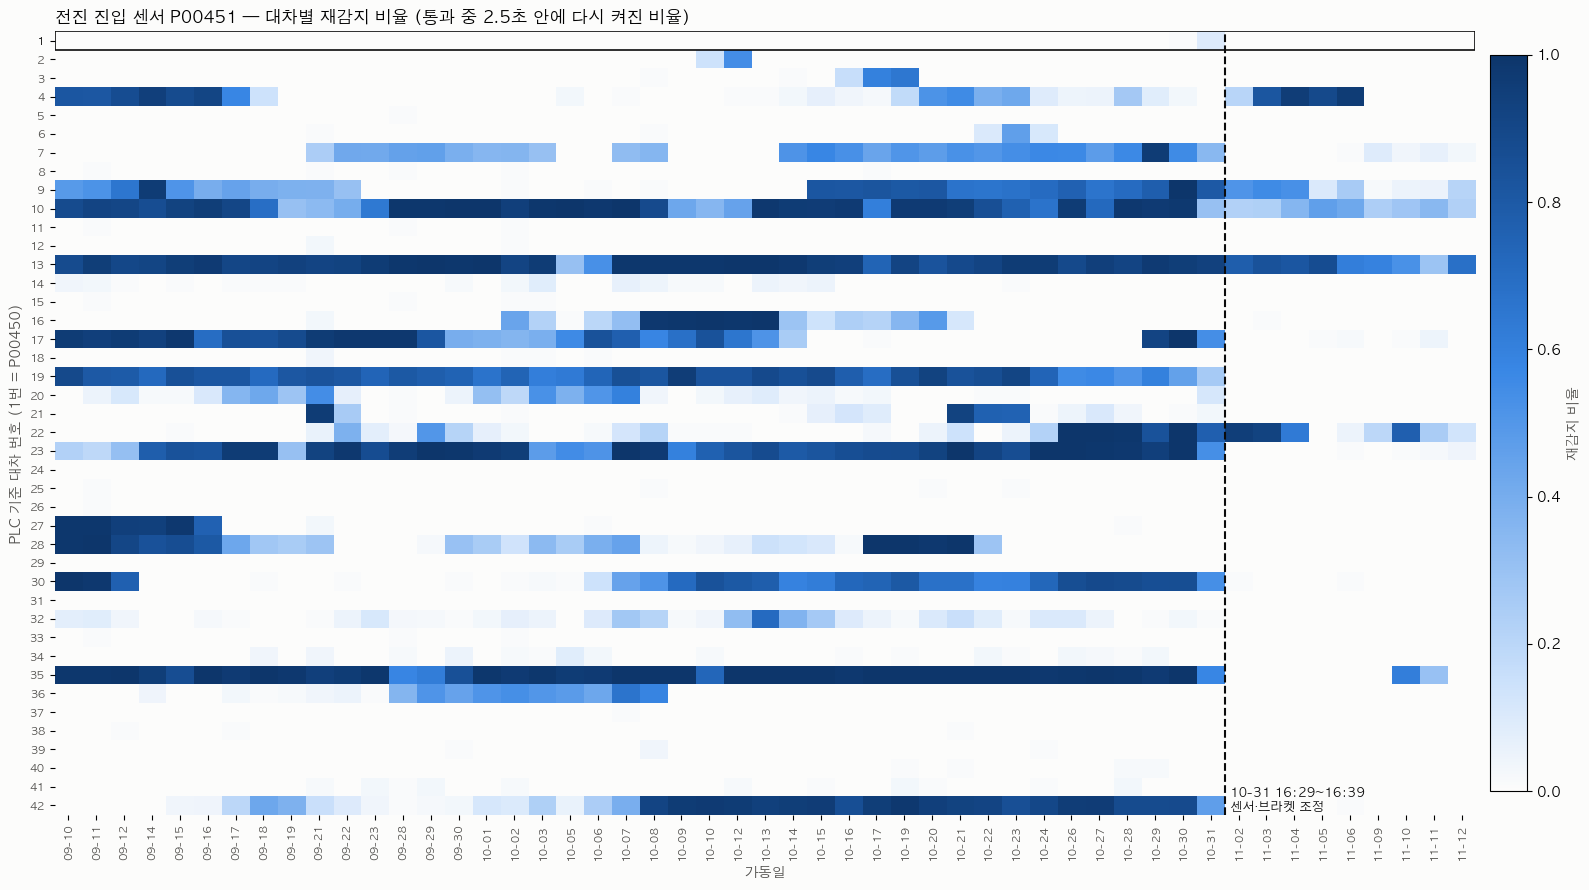

In [8]:
p = MP[(MP.unit == "fwd") & MP.wagon.notna()]
H1 = p.groupby(["wagon", "day"]).rearm.mean().unstack().reindex(range(1, 43))
seq = LinearSegmentedColormap.from_list("seq", ["#fcfcfb", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
fig, ax = plt.subplots(figsize=(16, 9), facecolor="#fcfcfb")
im = ax.imshow(H1.values, aspect="auto", cmap=seq, vmin=0, vmax=1, interpolation="nearest")
ax.set_yticks(range(42)); ax.set_yticklabels([str(w) for w in H1.index], fontsize=8, color="#52514e")
ax.get_yticklabels()[0].set_fontweight("bold"); ax.get_yticklabels()[0].set_color("#0b0b0b")
ax.set_xticks(range(len(H1.columns))); ax.set_xticklabels(H1.columns, rotation=90, fontsize=8, color="#52514e")
i31 = list(H1.columns).index("10-31")
ax.axvline(i31 + 0.5, color="#0b0b0b", lw=1.5, ls="--")
ax.text(i31 + 0.7, 41.4, "10-31 16:29~16:39\n센서·브라켓 조정", fontsize=9, color="#0b0b0b", va="bottom")
ax.add_patch(plt.Rectangle((-0.5, -0.5), len(H1.columns), 1, fill=False, ec="#0b0b0b", lw=1.2))
ax.set_ylabel("PLC 기준 대차 번호 (1번 = P00450)", color="#52514e"); ax.set_xlabel("가동일", color="#52514e")
ax.set_title("전진 진입 센서 P00451 — 대차별 재감지 비율 (통과 중 2.5초 안에 다시 켜진 비율)", loc="left", fontsize=12)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01); cb.set_label("재감지 비율", color="#52514e")
for s in ax.spines.values(): s.set_visible(False)
fig.tight_layout(); fig.savefig(FIGS / "C03_p451_rearm_heatmap.png", dpi=110, facecolor="#fcfcfb")

## 6. 조치 시점 (10-31 16:29 ~ 16:39)

10-31 오후를 정지·수동 운전 구간으로 나눠 재감지율과 재감지 대차를 본다.
공무반 점검(12:00~12:30, 13:30~14:00) 뒤에도 불일치는 6번 더 났다. **16:28이 마지막이다.**
16:29:42 ~ 16:30:07 짧은 정지 뒤 42·7·10·35·1번의 재감지가 사라졌고, 16:37:43 ~ 16:38:40 수동 운전 뒤에는 9·13·22번만 남았다.
기계실 기록 "기존 센서 및 브라켓 위치 조정"이 이 무렵이다(일지에 시각 없음).

In [9]:
x = p31[(p31.t >= "2026-10-31 15:00") & (p31.t < "2026-10-31 18:00")].copy()
cuts = pd.to_datetime(["2026-10-31 15:00:00", "2026-10-31 16:29:42", "2026-10-31 16:30:07", "2026-10-31 16:37:43",
                       "2026-10-31 16:38:40", "2026-10-31 18:00:00"], format="ISO8601")
x["구간"] = pd.cut(x.t, cuts, right=False, labels=["15:00~16:29 (조정 전)", "16:29:42 정지 25초", "16:30~16:37 자동",
                                                 "16:37:43 수동 운전", "16:38:40~18:00 (조정 후)"])
x.groupby("구간", observed=False).apply(lambda g: pd.Series({
    "통과": len(g), "재감지율": round(g.rearm.mean(), 3) if len(g) else None,
    "재감지 대차": " ".join(str(int(v)) for v in sorted(g[g.rearm & g.wagon.notna()].wagon.unique()))}), include_groups=False)

,통과,재감지율,재감지 대차
구간,,,
15:00~16:29 (조정 전),378,0.220,1 7 9 10 13 17 19 20 22 23 30 35 42
16:29:42 정지 25초,0,NaN,
16:30~16:37 자동,35,0.143,9 13 17 23 30
16:37:43 수동 운전,5,0.000,
16:38:40~18:00 (조정 후),324,0.049,9 13 22


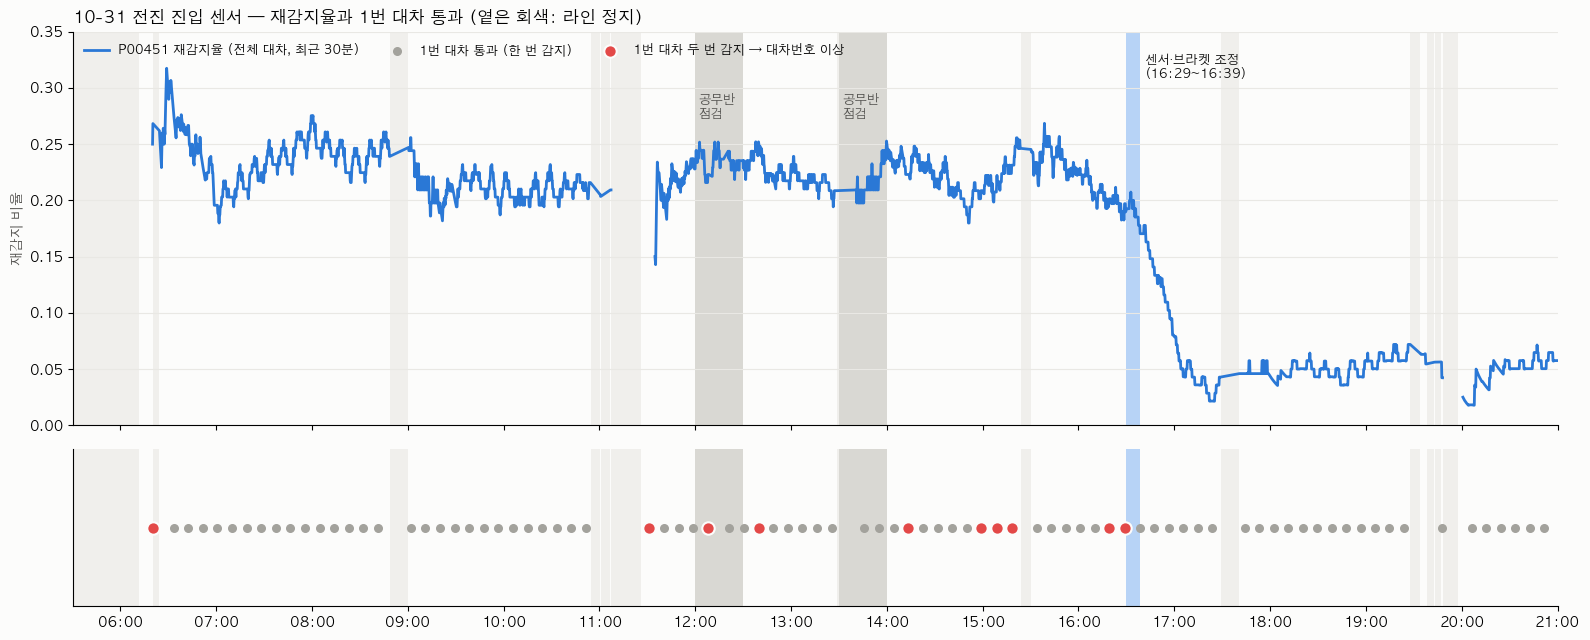

In [10]:
run = r31.Conv_Run_Out.fillna(0); ch = run.index[run.diff().fillna(0) != 0]
STOPS = [(a, b) for a, b in zip(ch[:-1], ch[1:]) if run[a] == 0 and (b - a).total_seconds() > 60]
q = p31[(p31.t >= "2026-10-31 05:00") & (p31.t < "2026-10-31 21:00")].set_index("t")
roll = q.rearm.rolling("30min", min_periods=40).mean()     # 정지 직후 통과가 적을 때는 그리지 않는다
w1 = q[q.wagon == 1]
fig, (a1, a2) = plt.subplots(2, 1, figsize=(16, 6.5), sharex=True, gridspec_kw=dict(height_ratios=[3, 1.2]), facecolor="#fcfcfb")
for ax in (a1, a2):
    ax.set_facecolor("#fcfcfb")
    for a, b in STOPS:
        ax.axvspan(a, b, color="#f0efec", lw=0)
    for a, b in LOG_TIMES:
        ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color="#d9d8d3", lw=0)
    ax.axvspan(*ADJ, color="#b7d3f6", lw=0)
    for s in ["top", "right"]: ax.spines[s].set_visible(False)
a1.plot(roll.index, roll.values, color="#2a78d6", lw=2, label="P00451 재감지율 (전체 대차, 최근 30분)")
a1.set_ylabel("재감지 비율", color="#52514e"); a1.set_ylim(0, 0.35); a1.grid(axis="y", color="#e9e8e4", lw=0.8)
a1.text(pd.Timestamp("2026-10-31 12:02"), 0.295, "공무반\n점검", fontsize=9, color="#52514e", va="top")
a1.text(pd.Timestamp("2026-10-31 13:32"), 0.295, "공무반\n점검", fontsize=9, color="#52514e", va="top")
a1.text(ADJ[1] + pd.Timedelta("3min"), 0.33, "센서·브라켓 조정\n(16:29~16:39)", fontsize=9, color="#0b0b0b", va="top")
a2.scatter(w1[~w1.rearm].index, np.zeros((~w1.rearm).sum()), s=30, color="#a3a29c", label="1번 대차 통과 (한 번 감지)", zorder=3)
a2.scatter(w1[w1.rearm].index, np.zeros(w1.rearm.sum()), s=80, color="#e34948", ec="#fcfcfb", lw=1.5,
           label="1번 대차 두 번 감지 → 대차번호 이상", zorder=4)
a2.set_yticks([]); a2.set_ylim(-1, 1)
a2.set_xlim(pd.Timestamp("2026-10-31 05:30"), pd.Timestamp("2026-10-31 21:00"))
a2.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M")); a2.xaxis.set_major_locator(mdates.HourLocator(interval=1))
h1, l1 = a1.get_legend_handles_labels(); h2, l2 = a2.get_legend_handles_labels()
a1.legend(h1 + h2, l1 + l2, loc="upper left", frameon=False, fontsize=9, ncol=3)
a1.set_title("10-31 전진 진입 센서 — 재감지율과 1번 대차 통과 (옅은 회색: 라인 정지)", loc="left", fontsize=12)
fig.tight_layout(); fig.savefig(FIGS / "C03_1031_timeline.png", dpi=110, facecolor="#fcfcfb")

## 7. 모델 — 가동일 기록 판정: P00451 "센서 재감지"는 9-10부터 매일 켜져 있었다

`sensor_level`: 통과당 재감지 0.1 이상인 대차가 **10대 이상**이면 센서 플래그 "센서 재감지"(권고: 센서 감지 거리·위치 확인).
플래그가 켜진 센서는 그 센서의 대차 경고를 모두 센서 경고 하나로 묶는다(`absorbed_by_sensor`).

- 09-10 ~ 10-31 모든 가동일 재감지 대차 15~25대 → 플래그 매일 켜짐. 조치 뒤 11-02 9대 · 11-03 9대 · 11-04 10대 · 11-05 6대.
- 1번 대차 칸은 10-31도 재감지 0.1 → `정상`이다. 모델은 1번을 다른 대차와 똑같이 본다(문턱 0.5).

In [11]:
backend.use("v2.2")
from tools_yeji.conveyor_models.core_judge import judge, sensor_level
from tools_yeji.conveyor_models.core_params import LONG_REF
Hd = pd.DataFrame(HIST); Hd["day"] = pd.to_datetime(Hd.day)
J = judge(Hd)
_, LV = sensor_level(J, pd.DataFrame([{"sensor": s, **v} for s, v in LONG_REF.items()]))
lv = LV[LV.sensor == "P00451"].assign(day=lambda d: d.day.dt.strftime("%m-%d"))[["day", "D", "W0", "rearm", "n_rearm", "flag"]]
lv.set_index("day").T

day,09-10,09-11,09-12,09-14,09-15,09-16,09-17,09-18,09-19,09-21,09-22,09-23,09-28,09-29,09-30,10-01,10-02,10-03,10-05,10-06,10-07,10-08,10-09,10-10,10-12,10-13,10-14,10-15,10-16,10-17,10-19,10-26,10-27,10-28,10-29,10-30,10-31,11-02,11-03,11-04,11-05
D,3758.0,3758.0,3758.0,3758.0,3758.0,3758.0,3758.0,3758.0,3758.0,3758.0,3758.0,3758.0,3758.0,3758.0,3758.0,3758.0,3758.0,3758.0,3758.0,3758.0,3758.0,3758.0,3758.0,3758.0,3758.0,3759.0,3758.5,3758.0,3759.0,3759.0,3759.0,3759.0,3759.0,3758.0,3758.0,3758.0,3758.0,3759.0,3759.0,3759.0,3759.0
W0,9.0,9.0,9.0,8.0,8.0,9.0,8.5,9.0,9.0,9.0,8.25,9.0,8.0,9.0,9.0,9.0,9.0,8.5,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,8.0,9.0,9.0,8.5,8.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,8.75,9.0,8.5
rearm,0.377114,0.380746,0.368758,0.324746,0.316999,0.323964,0.337572,0.307134,0.268207,0.370889,0.322308,0.268506,0.294109,0.307044,0.338973,0.344929,0.399357,0.379231,0.256059,0.322912,0.459652,0.422776,0.320469,0.325675,0.378013,0.378467,0.383835,0.398478,0.390638,0.438056,0.435989,0.332463,0.324627,0.347348,0.37837,0.386349,0.246112,0.104553,0.117428,0.110798,0.071254
n_rearm,23,23,23,18,19,20,20,20,18,22,20,15,16,15,18,18,21,23,17,22,24,23,19,21,23,22,23,23,23,23,25,18,17,18,19,19,19,9,9,10,6
flag,센서 재감지,센서 재감지,센서 재감지,센서 재감지,센서 재감지,센서 재감지,센서 재감지,센서 재감지,센서 재감지,센서 재감지,센서 재감지,센서 재감지,센서 재감지,센서 재감지,센서 재감지,센서 재감지,센서 재감지,센서 재감지,센서 재감지,센서 재감지,센서 재감지,센서 재감지,센서 재감지,센서 재감지,센서 재감지,센서 재감지,센서 재감지,센서 재감지,센서 재감지,센서 재감지,센서 재감지,센서 재감지,센서 재감지,센서 재감지,센서 재감지,센서 재감지,센서 재감지,,,센서 재감지,


In [12]:
# 대차 칸 (P00451) — 1번과, 조치 전후로 경고에 나온 대차
WS = [1, 42, 7, 9, 10, 13, 22, 30, 4]
j = J[(J.sensor == "P00451") & J.wagon.isin(WS) & (J.day >= "2026-10-26")]
pd.concat({c: j.pivot_table(index="wagon", columns=j.day.dt.strftime("%m-%d"), values=c, aggfunc="first").reindex(WS)
           for c in ["state", "rearm", "rise_off", "width_ex"]}, axis=1).round(1)

state                                                                         rearm                                                       rise_off                                                       width_ex                                \
day     10-26   10-27   10-28   10-29   10-30   10-31   11-02   11-03   11-04   11-05 10-26 10-27 10-28 10-29 10-30 10-31 11-02 11-03 11-04 11-05    10-26 10-27 10-28 10-29 10-30 10-31 11-02 11-03 11-04 11-05    10-26 10-27 10-28 10-29 10-30 10-31   
wagon                                                                                                                                                                                                                                                     
1          정상      정상      정상      정상      정상      정상      정상      정상      정상      정상   0.0   0.0   0.0   0.0   0.0   0.1   0.0   0.0   0.0   0.0      0.0  -1.0   0.0   0.0   1.0   1.0  -1.0   0.0   0.0  -1.0      0.0   0.0  -1.0  -1.0  -1.0   0.0   
42     이물(분리)  이물(분리)  이물(분리)  이물(분리)  이물(분리)  이물(분리)      정상      정상      정상      정상   0.9   0.9   1.0   1.0   0.9   0.6   0.0   0.0   0.0   0.0    -15.0 -15.0 -14.0 -14.0 -14.0  -6.0  -1.0  -1.0  -1.0  -1.0      6.0   9.0  12.0  12.5   6.0   2.5   
7      이물(분리)  이물(분리)  이물(분리)  이물(분리)  이물(분리)  이물(분리)   위치 변화     흔들림      정상     흔들림   1.5   1.4   1.4   1.3   1.5   0.8   0.1   0.1   0.0   0.0    -15.0 -15.0 -14.0 -14.0 -14.0  -6.0  -7.0  -1.0  -1.0  -1.0      6.0   6.0   6.0   5.0   6.0   5.0   
9      이물(분리)  이물(분리)  이물(분리)  이물(분리)  이물(분리)  이물(분리)  이물(분리)  이물(분리)  이물(분리)   이물(앞)   1.4   1.4   1.6   1.6   1.7   1.3   0.9   0.8   0.8   0.3    -15.0 -15.0 -14.0 -14.0 -14.0 -13.0  -6.0 -10.0 -11.0  -7.0     10.0   9.5  11.0  10.0   5.0   2.5   
10     이물(분리)  이물(분리)  이물(분리)  이물(분리)  이물(분리)  이물(분리)   이물(앞)   이물(앞)  이물(분리)  이물(분리)   1.4   1.2   1.5   1.5   1.3   0.8   0.4   0.4   0.5   0.6    -14.0 -14.0 -13.0 -13.0 -13.0  -6.0  -5.0  -5.0  -5.0  -5.0      5.0   5.5   5.0  10.0   6.0   5.0   
13     이물(분리)  이물(분리)  이물(분리)  이물(분리)  이물(분리)  이물(분리)  이물(분리)  이물(분리)  이물(분리)  이물(분리)   1.5   1.4   1.4   1.5   1.4   1.0   0.7   0.8   0.8   0.7    -15.0 -15.0 -14.0 -14.0 -14.0 -13.0 -13.5 -14.0 -12.0 -14.0     12.0   6.5   6.0   6.0   8.0   4.0   
22     이물(분리)  이물(분리)  이물(분리)  이물(분리)  이물(분리)  이물(분리)  이물(분리)  이물(분리)  이물(분리)      정상   1.6   1.7   1.6   1.7   1.7   1.4   1.4   1.2   0.9   0.0    -15.0 -15.0 -14.0 -14.0 -14.0 -14.0 -14.0 -14.0  -7.0   0.0      5.0   6.0   5.0   6.0   5.0   6.0   
30     이물(분리)  이물(분리)  이물(분리)  이물(분리)  이물(분리)  이물(분리)   이물(앞)   이물(앞)   이물(앞)   이물(앞)   1.0   1.0   1.0   1.1   1.0   0.5   0.1   0.2   0.1   0.2    -14.0 -14.0 -13.0 -13.0 -14.0  -6.0  -6.0  -6.0  -6.0  -6.0     12.0   6.0  12.0  10.5  10.0   6.0   
4          정상      정상      정상      정상      정상      정상      정상  이물(분리)  이물(분리)  이물(분리)   0.0   0.0   0.2   0.1   0.0   0.0   0.2   0.8   0.9   0.9     -1.0  -1.0   0.0   0.0   0.0   0.0  -1.0 -14.0 -15.0 -14.0      0.0   0.0   0.0   0.0   0.0   0.0   

                               
day   11-02 11-03 11-04 11-05  
wagon                          
1       0.0   0.2   0.0   0.5  
42      0.0   0.2   0.0   0.5  
7       1.0   0.2   0.0   1.0  
9       0.0   1.8   0.0   6.5  
10      3.0   5.2   2.0   2.5  
13      4.0   2.2   2.0  11.5  
22      5.0   4.2   0.0  -1.0  
30      5.0   5.2   5.0   4.5  
4       0.0   4.2  11.0   1.5

## 8. 실제 엣지 경고

컨베이어 경고 로그는 10-26 06:19에 시작했다. **W0069 "P00451 센서 재감지 → 센서 감지 거리·위치 확인"이 첫 판정(10-26 07:06)부터 떴다.**
10-31 20:27까지 켜져 있다가 꺼졌다(23:58 해제). 조정(16:29~16:39) 뒤 약 4시간이다. 칸은 최근 20번 통과(약 3시간)라 그만큼 늦는다.
꺼진 바로 그 순간(20:25:56) 묶여 있던 대차 경고 W0171이 풀려 나왔다. `since`가 09-10·10-07이다 — 오래된 칸이다.

In [13]:
ep = pd.read_csv(paths.EPISODES_DIR / "warning_episodes.csv", low_memory=False)
cv = ep[(ep.kind == "conveyor") & ep.key.str.contains("P00451|md_fwd")]
cv[["episode_id", "key", "onset", "last_detected", "cleared", "wagon_nos", "reasons", "n_events", "model_ver"]]

,episode_id,key,onset,last_detected,cleared,wagon_nos,reasons,n_events,model_ver
68,W0069,P00451,2026-10-26 07:06:19.433,2026-10-31 20:25:55.822,2026-10-31 23:58:00.109,NaN,sensor_rearm,3,v2.1
80,W0081,md_fwd,2026-10-26 14:38:35.787,2026-10-28 14:38:20.494,2026-10-28 17:30:00.228,NaN,air_time_slow,3,v2.1
113,W0114,md_fwd,2026-10-28 20:15:11.370,2026-10-29 18:00:12.136,2026-10-29 22:10:00.398,NaN,air_time_slow,13,v2.1
147,W0148,md_fwd,2026-10-30 14:42:15.605,2026-11-06 14:33:02.229,NaN,NaN,air_time_slow,6,v2.1
170,W0171,P00451:wagons,2026-10-31 20:25:56.340,2026-11-02 22:26:52.019,2026-11-03 08:50:00.024,7;10;13;29;30;33,wagon_debris_front,30,v2.1
188,W0189,P00451,2026-11-02 22:26:52.529,2026-11-04 07:11:46.858,2026-11-04 10:50:00.989,NaN,sensor_rearm,7,v2.1
202,W0203,P00451:wagons,2026-11-03 14:53:26.355,2026-11-03 15:38:37.334,2026-11-03 19:30:00.377,4;9;10;13;22,wagon_rearm,4,v2.1
207,W0208,P00451:wagons,2026-11-03 20:41:27.864,2026-11-04 15:17:09.812,2026-11-04 17:30:00.798,4;9;10;13;22,wagon_rearm,8,v2.1
222,W0223,P00451,2026-11-04 15:17:10.326,2026-11-04 21:09:40.970,2026-11-04 23:58:00.177,NaN,sensor_rearm,5,v2.1
223,W0224,P00451:wagons,2026-11-04 17:44:52.590,2026-11-06 14:44:05.707,NaN,4;9;10;13;22,wagon_rearm,27,v2.1


In [14]:
ev = pd.read_csv(paths.EPISODES_DIR / "warning_events.csv", low_memory=False, parse_dates=["ts"])
e = ev[(ev.kind == "conveyor") & ev.key.astype(str).str.startswith("P00451") & ev.ts.between("2026-10-26", "2026-11-01")]
e[["ts", "event", "key", "active", "since", "wagon_nos", "message"]]

,ts,event,key,active,since,wagon_nos,message
3320,2026-10-26 07:06:19.432,raised,P00451,True,NaN,NaN,센서 재감지: 대차 여러 대에서 표식 앞까지 감지 → 센서 감지 거리·위치 확인
6698,2026-10-31 20:25:56.340,raised,P00451:wagons,True,10-07,7;29;30,전진Unit 캐리어 진입감지 대차 07·29·30: 앞 끝·켜짐 길이 변화 → 표식...
6699,2026-10-31 20:27:26.027,updated,P00451,False,NaN,NaN,센서 재감지: 대차 여러 대에서 표식 앞까지 감지 → 센서 감지 거리·위치 확인
6700,2026-10-31 20:27:56.951,updated,P00451:wagons,True,10-07,7;30,전진Unit 캐리어 진입감지 대차 07·30: 앞 끝·켜짐 길이 변화 → 표식 앞쪽 이물
6711,2026-10-31 22:07:27.511,updated,P00451:wagons,True,09-10,7;10;30,전진Unit 캐리어 진입감지 대차 07·10·30: 앞 끝·켜짐 길이 변화 → 표식...
6718,2026-10-31 23:58:00.109,cleared,P00451,False,NaN,NaN,센서 재감지: 대차 여러 대에서 표식 앞까지 감지 → 센서 감지 거리·위치 확인


## 9. 조치 뒤 경고 — 같은 원인의 잔여

- 조치로 대부분 대차의 "표식 14카운트 앞" 재감지가 사라졌다(42·7번 등 → 앞 끝 −1). 하지만 10·30번은 앞 끝 −6, 켜짐 길이 +5로 남았다.
  센서가 이제 7카운트 앞 구조물을 표식과 이어서 하나의 긴 펄스로 본다 → `이물(앞)` → W0171.
- 4·9·13·22번은 14카운트 앞 재감지가 계속된다(4번은 11-03부터 다시 80~96%). 재감지 대차가 9~10대를 오가 센서 플래그가 켜졌다 꺼졌다 한다
  → W0189·W0223·W0318(센서) ↔ W0203·W0208·W0224·W0274(대차).
- **어느 것도 1번 대차가 아니다** → PLC 번호 이상은 다시 나지 않았다(11-12까지 0).

In [15]:
post = MP[(MP.unit == "fwd") & MP.wagon.notna() & (MP.day >= "11-02")]
r = post.groupby(["wagon", "day"]).rearm.mean().unstack()
r[r.max(axis=1) >= 0.1].round(2)

day,11-02,11-03,11-04,11-05,11-06,11-09,11-10,11-11,11-12
wagon,,,,,,,,,
4,0.21,0.82,0.95,0.89,0.96,0.00,0.00,0.00,0.00
9,0.51,0.55,0.53,0.10,0.25,0.02,0.05,0.05,0.21
10,0.22,0.23,0.36,0.46,0.42,0.24,0.28,0.34,0.23
13,0.78,0.84,0.82,0.87,0.61,0.59,0.52,0.29,0.68
22,0.95,0.92,0.63,0.00,0.05,0.19,0.77,0.25,0.13
35,0.00,0.00,0.00,0.00,0.00,0.00,0.61,0.30,0.00


## 10. 같은 유닛의 주입 시간 경고(W0148)는 무관

W0081 · W0114 · W0148 `md_fwd air_time_slow`(10-26 ~ 11-06)가 C03 앞뒤로 떠 있다. 같은 유닛이지만
40.5 Hz 사이클만 보면 전진 Unit 주입 시간은 10-26 ~ 11-05 내내 0.58초로 평탄하고 조치 전후도 같다. 진입 센서 재감지와 관계없다.
(C02 노트북의 엣지 조건 재생 캐시 `c02_edge_1026_1105.pkl`을 쓴다)

In [16]:
R = pd.read_pickle(RCACHE / "c02_edge_1026_1105.pkl")
m = R["cycles"]; m = m[m.unit == "md_fwd"].copy(); m["t"] = pd.to_datetime(m.t)
hz = R["hz"].Hz; hz = hz[~hz.index.duplicated()]
m["hz"] = hz.reindex(m.t, method="ffill").values
m = m[m.hz == 405]
m["구간"] = np.where(m.t < "2026-10-31 16:30", "조치 전", "조치 후")
print(m.groupby(m.t.dt.strftime("%m-%d")).agg(n=("air_time", "count"), air_time=("air_time", "mean"),
                                            drag_cnt=("drag_cnt", "mean")).round(3).T.to_string())
m[m.t.between("2026-10-31 12:00", "2026-10-31 21:00")].groupby("구간")[["air_time", "drag_cnt", "catch_cnt", "nozzle_rev_time"]].mean().round(3)

t            10-26     10-27     10-28     10-29     10-30     10-31   11-01     11-02     11-03     11-04     11-05
n         3299.000  3082.000  3194.000  3287.000  2931.000  3312.000  40.000  3336.000  2969.000  2886.000  3499.000
air_time     0.576     0.586     0.578     0.581     0.583     0.583   0.642     0.581     0.577     0.584     0.582
drag_cnt    12.303    12.367    12.298    12.310    12.286    12.338  12.388    12.303    12.277    12.325    12.266


,air_time,drag_cnt,catch_cnt,nozzle_rev_time
구간,,,,
조치 전,0.583,12.386,6.420,0.315
조치 후,0.582,12.370,6.279,0.322


## 11. 후진 쪽 같은 사례 — 09-14 1번 대차 센터축 볼트

09-14 05:18 ~ 07:31 후진 번호 불일치(`M00045`) 8번, 모두 PLC 기준 1번 대차의 앞 펄스(1.0~1.7초 앞, 카운터 119~120에서 리셋) 뒤였다.
일지: 07:30~08:30 "중형 후진 에어주입장치 센서 에러 → **1번 대차 센터축 고정 볼트 파손** 확인", 10:50~11:30 볼트 교체.
07:31 뒤로 멈췄다. 같은 원리(1번 대차 재감지 → 두 번 셈)이고, 이번에는 원인이 대차 쪽(볼트)이었다.

In [17]:
r14 = raw_day("2026-09-14")
mismatch_events(r14, md_passes(r14, "R00060", "P00458"), bit="M00045", latch="M00611")

,불일치,통과 시작(앞 펄스),PLC 대차,앞 펄스→본 감지(초),리셋 직전 카운터,1번 감지 누락 비트,라인 정지,번호 복구
0,05:18:32,05:18:30,1,1.60,120,1,05:18:41,NaN
1,06:27:52,06:27:51,1,1.01,123,1,06:28:01,06:28:51
2,06:38:03,06:38:02,1,1.02,123,1,06:38:12,06:39:20
3,06:48:34,06:48:32,1,1.55,121,1,06:48:41,06:49:58
4,06:59:14,06:59:13,1,1.04,124,1,06:59:59,06:59:30
5,07:12:37,07:12:36,1,1.06,124,1,07:13:22,07:12:48
6,07:21:53,07:21:52,1,1.03,124,1,07:22:51,07:22:15
7,07:31:07,07:31:05,1,1.03,122,1,07:32:04,07:31:31


## 12. 결론

1. **"전진 대차번호 이상"은 1번 대차에서 P00451이 두 번 켜진 결과다.** PLC는 다른 대차의 재감지를 2회 방지로 거르지만,
   1번 대차에서는 1번 감지 센서(P00450)가 그 방지를 풀어 두 번 센다. 10-30 1번, 10-31 10번 — 불일치 11번이 모두 그 순간이다.
2. P00451은 9월부터 하루 8~15대(모델 기준 15~25대)에서 표식 7·14카운트 앞 구조물까지 감지해 왔다. 1번 대차에 그것이 생긴 것이 10-30 20:07이다.
3. 현장 조치(센서·브라켓 위치 조정, 16:29~16:39)로 재감지율이 0.22 → 0.05로 떨어졌고 1번 대차 이중 감지는 11-12까지 0이다.
4. **모델은 원인을 짚고 있었다.** W0069 "P00451 센서 재감지 → 센서 감지 거리·위치 확인"이 10-26 첫 판정부터 떠 있었고, 조치 4시간 뒤 꺼졌다.
   권고와 실제 조치가 같다 → `TP`(부위 일치). 다만 9-10부터 매일 켜진 상시 경고라 "언제 서는지"는 알려 주지 못했다.
5. **놓친 것: 1번 대차의 재감지.** PLC가 약한 곳은 1번 대차 하나뿐이다. 1번 칸에 재감지가 한 번이라도 생기면 곧 라인이 선다.
   모델은 1번을 다른 대차와 같이 문턱 0.5로 보고, 센서 플래그에 묶어 버린다 → 모델 수정 예정 C-05.
6. 조치 뒤 경고(W0171 · W0189 …)는 같은 원인의 잔여다. 1번이 아니라 PLC 영향은 없지만 센서가 아직 일부 대차에서 표식 앞을 본다.